# Smart Parking Violation Detection — Six Priority Campus Categories
**Deep Learning & Computer Vision Lab Academic Project**

## 1. Problem Statement & Project Objectives
College campuses frequently encounter traffic bottlenecks, pedestrian safety hazards, and emergency access blockages due to disorganized vehicle parking. Manual patrolling of sprawling campuses is labor-intensive, error-prone, and inefficient.

### Objective:
Develop an end-to-end computer vision and deep learning pipeline that automatically identifies **Six Priority Campus Parking Violation Categories** from camera images, extracts vehicle number plates via OCR, validates permissions against a campus SQLite authorization database, and prepares human-in-the-loop advisory notices.

### The Six Priority Violation Categories:
1. **Category 1: Unauthorized Parking / No-Parking Zones** — Identifies vehicles occupying designated red curb fire lanes, fire hydrant buffers, or clearly marked restricted zones. (Explicitly avoids false positives when a vehicle is merely driving past a no-parking road sign).
2. **Category 2: Footpath Parking** — Detects cars and motorcycles mounted on pedestrian walkways or sidewalks.
3. **Category 3: Blocking Entrances & Emergency Access** — Detects vehicles obstructing college gates, building entrances, and yellow hatched clearance boxes.
4. **Category 4: Parking on Green Spaces** — Detects vehicles occupying campus lawns and landscaped vegetative turf.
5. **Category 5: Improper Parking Alignment** — Identifies vehicles straddling painted stall divider lines or occupying multiple parking spaces.
6. **Category 6: Wrong Parking Slot** — Identifies vehicles occupying reserved faculty, staff, visitor, or principal slots without matching database authorization.

### Three-State Classification Standard:
Each category yields one of three transparent outcomes:
- **`Potential violation detected`**: Sufficient visual and spatial evidence confirms the violation.
- **`Not detected`**: Available evidence confirms compliance.
- **`Review required`**: Ambiguous boundaries, faded lines, unreadable plate, or uncalibrated camera angle require manual human review.

## 2. Environment Setup & Library Imports
The pipeline leverages modern deep learning and computer vision libraries:
- **Ultralytics YOLOv8**: Real-time object detection for vehicles (cars, motorcycles, buses, trucks) and license plates.
- **OpenCV & NumPy**: Perspective analysis, Hough Line Transform, HSV color segmentation, and morphological filtering.
- **EasyOCR**: Optical character recognition for license plates and pavement markings.
- **SQLite**: Embedded database for vehicle registration, role-based authorization, and notification audit logs.

In [1]:
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Add project root to sys.path
project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import project modules
import config
from database import init_db, get_parking_authorization, check_slot_authorization
from registry import lookup_plate, register_vehicle, get_all_vehicles
from parking_detector import (
    get_vehicle_model,
    detect_vehicles_and_violations,
    detect_scene_visual_evidence,
    calculate_ground_contact_point
)
from campus_violation_engine import (
    detect_footpath_regions,
    detect_entrance_clearance_corridors,
    detect_lawn_green_spaces,
    detect_parking_stall_lines,
    detect_reserved_slot_markings,
    evaluate_all_campus_violations
)
from plate_reader import (
    get_plate_detector,
    get_ocr_reader,
    read_plate_from_vehicle_crop
)

# Initialize SQLite database
init_db()
print("Environment initialized successfully!")
print(f"Vehicle Model: {config.VEHICLE_MODEL_PATH}")
print(f"Plate Model:   {config.PLATE_MODEL_PATH}")
print(f"Database:      {config.DB_PATH}")

Environment initialized successfully!
Vehicle Model: D:\DL Project\models\yolov8n.pt
Plate Model:   D:\DL Project\models\license_plate_detector.pt
Database:      D:\DL Project\data\parking_system.db


## 3. Loading and Displaying Campus Test Images
We load test scenes representing various campus parking layouts, walkways, entrance gates, lawns, and reserved bays.

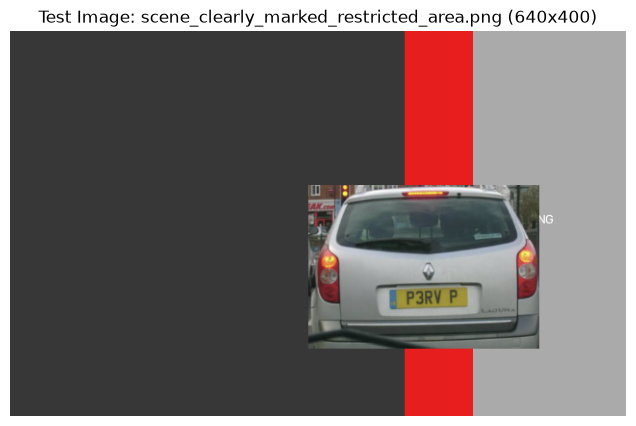

In [2]:
sample_image_path = Path("data/test_images/scene_clearly_marked_restricted_area.png")
assert sample_image_path.exists(), f"Image not found at {sample_image_path}"

img_bgr = cv2.imread(str(sample_image_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w, _ = img_rgb.shape

plt.figure(figsize=(9, 5))
plt.imshow(img_rgb)
plt.title(f"Test Image: {sample_image_path.name} ({w}x{h})", fontsize=12)
plt.axis("off")
plt.show()

## 4. Vehicle Detection Using Pretrained YOLOv8
We utilize YOLOv8 pretrained on MS-COCO to detect campus vehicle classes:
- `car` (Class ID 2)
- `motorcycle` (Class ID 3)
- `bus` (Class ID 5)
- `truck` (Class ID 7)

### Ground-Contact Point Approximation:
Rather than evaluating bounding-box Intersection-over-Union (IoU) — which erroneously includes vehicle roofs and shadows — we compute the vehicle's bottom-center coordinate $( (x_1+x_2)/2, y_2 )$, representing where tires contact the ground.

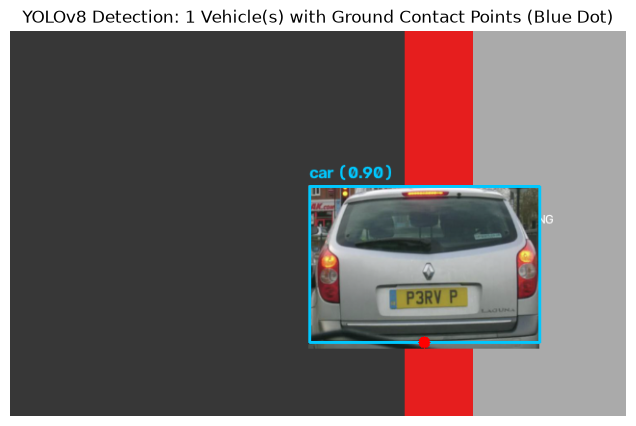

In [3]:
vehicle_model = get_vehicle_model()
results = vehicle_model.predict(
    source=img_rgb,
    conf=0.25,
    classes=list(config.VEHICLE_CLASSES.keys()),
    verbose=False
)

annotated_vis = img_rgb.copy()
detected_boxes = []

if len(results) > 0 and results[0].boxes is not None:
    for box in results[0].boxes:
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].cpu().numpy()]
        cls_id = int(box.cls[0].cpu().numpy())
        conf = float(box.conf[0].cpu().numpy())
        cls_name = config.VEHICLE_CLASSES.get(cls_id, "vehicle")
        gx, gy = calculate_ground_contact_point((x1, y1, x2, y2))
        detected_boxes.append((x1, y1, x2, y2))

        cv2.rectangle(annotated_vis, (x1, y1), (x2, y2), (0, 200, 255), 2)
        cv2.circle(annotated_vis, (gx, gy), 6, (255, 0, 0), -1)
        cv2.putText(annotated_vis, f"{cls_name} ({conf:.2f})", (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 255), 2)

plt.figure(figsize=(9, 5))
plt.imshow(annotated_vis)
plt.title(f"YOLOv8 Detection: {len(detected_boxes)} Vehicle(s) with Ground Contact Points (Blue Dot)")
plt.axis("off")
plt.show()

## 5. Scene Segmentation & Restricted-Region Identification
Automatic scene understanding detects infrastructure boundaries without requiring users to manually draw polygons:
1. **Footpaths / Sidewalks**: Segmented via pavement texture and curb line edges.
2. **Entrance Clearance Corridors**: Detected via yellow hatched cross-striping and portal bounding boxes.
3. **Campus Lawns & Green Spaces**: Identified using HSV color masking combined with Laplacian texture variance to distinguish real grass turf from smooth green painted surfaces.
4. **Parking Stall Lines**: Detected using Hough Line Transform on road asphalt, filtering out car body edges to identify true pavement stall dividers.
5. **Reserved Pavement Markings**: OCR detection of keywords like `FACULTY`, `STAFF`, `PRINCIPAL`, and `VISITOR`.

In [4]:
evidence = detect_scene_visual_evidence(img_rgb, vehicle_boxes=detected_boxes)
print("Detected Scene Evidence:")
print(f"- Zone Status:       {evidence['zone_status']}")
print(f"- Active Zones:      {len(evidence['active_zones'])}")
print(f"- Footpaths:         {len(evidence['footpaths'])}")
print(f"- Entrance Corridors:{len(evidence['entrances'])}")
print(f"- Green Lawns:       {len(evidence['lawns'])}")
print(f"- Stall Markings:    {evidence['stall_data']}")
print(f"- Reserved Slots:    {evidence['reserved_slots']}")
for item in evidence['evidence_items']:
    print(f"  * {item}")

Detected Scene Evidence:
- Zone Status:       Confirmed Visual Evidence
- Active Zones:      1
- Footpaths:         1
- Entrance Corridors:0
- Green Lawns:       1
- Stall Markings:    {'divider_x_coords': [], 'is_reliable': False, 'vehicle_divider_continuations': []}
- Reserved Slots:    []
  * Confirmed: Broad Red No-Parking Surface Marking
  * Confirmed: Pedestrian Footpath / Sidewalk (1 region(s))
  * Confirmed: Campus Lawn / Landscaped Green Space (1 zone(s))


## 6. Demonstration of the Six Priority Violation Categories
We evaluate benchmark test images across all six priority categories using the unified master pipeline `detect_vehicles_and_violations`.

In [5]:
benchmark_scenes = [
    ("Category 1: Marked Restricted Area", "data/test_images/scene_clearly_marked_restricted_area.png"),
    ("Category 1: Passing Near Sign (No Violation)", "data/test_images/scene_near_no_parking_sign.png"),
    ("Category 2: Footpath Parking", "data/test_images/scene_cat2_footpath_parking.png"),
    ("Category 2: Footpath Compliant", "data/test_images/scene_cat2_footpath_compliant.png"),
    ("Category 3: Blocking Entrance Gate", "data/test_images/scene_cat3_blocking_entrance.png"),
    ("Category 3: Entrance Clearance Compliant", "data/test_images/scene_cat3_entrance_clear.png"),
    ("Category 4: Parking on Green Lawn", "data/test_images/scene_cat4_lawn_parking.png"),
    ("Category 4: Paved Parking (Beside Lawn)", "data/test_images/scene_cat4_paved_parking.png"),
    ("Category 5: Improper Alignment (Straddling Line)", "data/test_images/scene_cat5_improper_alignment.png"),
    ("Category 5: Compliant Stall Alignment", "data/test_images/scene_cat5_proper_alignment.png"),
    ("Category 6: Wrong Slot (Student in Principal Bay)", "data/test_images/scene_cat6_wrong_slot_unauthorized.png"),
    ("Category 6: Authorized Slot (Principal in Bay)", "data/test_images/scene_cat6_correct_slot_authorized.png")
]

print(f"{'SCENE':<48} | {'VEHICLES':<8} | {'OUTCOME':<12} | {'PRIMARY VIOLATION'}")
print("-" * 105)

for label, img_file in benchmark_scenes:
    p = Path(img_file)
    if not p.exists():
        continue
    res = detect_vehicles_and_violations(p)
    v_count = res["total_vehicles"]
    is_viol = (res["total_violations"] > 0)
    outcome = "VIOLATION" if is_viol else "COMPLIANT"

    viol_summary = "None"
    if v_count > 0:
        v = res["vehicles"][0]
        evals = v.get("campus_evaluations", {}).get("categories", {})
        active_cats = [cat["category_name"] for cat in evals.values() if cat.get("status") == "Potential violation detected"]
        if active_cats:
            viol_summary = ", ".join(active_cats)

    print(f"{label:<48} | {v_count:<8} | {outcome:<12} | {viol_summary}")

SCENE                                            | VEHICLES | OUTCOME      | PRIMARY VIOLATION
---------------------------------------------------------------------------------------------------------
Category 1: Marked Restricted Area               | 1        | VIOLATION    | Unauthorized Parking / No-Parking Zone
Category 1: Passing Near Sign (No Violation)     | 1        | COMPLIANT    | None
Category 2: Footpath Parking                     | 1        | VIOLATION    | Footpath Parking
Category 2: Footpath Compliant                   | 1        | COMPLIANT    | None
Category 3: Blocking Entrance Gate               | 1        | VIOLATION    | Blocking Entrances and Emergency Access
Category 3: Entrance Clearance Compliant         | 1        | COMPLIANT    | None
Category 4: Parking on Green Lawn                | 1        | VIOLATION    | Parking on Green Spaces
Category 4: Paved Parking (Beside Lawn)          | 1        | COMPLIANT    | None
Category 5: Improper Alignment (Straddling 

## 7. License Plate Detection & EasyOCR Recognition
For vehicles associated with potential violations, the dedicated plate detector localizes the license plate, crops it, and extracts text using EasyOCR with character normalization.

In [6]:
test_car_path = Path("data/test_images/car_sample_2.png")
car_bgr = cv2.imread(str(test_car_path))
car_rgb = cv2.cvtColor(car_bgr, cv2.COLOR_BGR2RGB)

plate_info = read_plate_from_vehicle_crop(car_rgb)

print("Plate Recognition Results:")
print(f"- Plate Detected:     {plate_info['plate_detected']}")
print(f"- Raw OCR Text:       '{plate_info['raw_text']}'")
print(f"- Normalized Plate:   '{plate_info['normalized_plate']}'")
print(f"- Confidence:         {plate_info.get('ocr_confidence', 0.0)}")
print(f"- Is Registered:      {plate_info.get('registry_record') is not None}")
if plate_info.get('registry_record'):
    rec = plate_info['registry_record']
    print(f"- Registered Owner:   {rec['owner_name']}")
    print(f"- Campus Role:        {rec['role']}")
    print(f"- Authorized Slots:   {rec['authorized_slots']}")
    print(f"- Notification Email: {rec['email']}")

Plate Recognition Results:
- Plate Detected:     True
- Raw OCR Text:       'P3RV P'
- Normalized Plate:   'P3RVP'
- Confidence:         0.763
- Is Registered:      True
- Registered Owner:   Faculty Vehicle (Test Scene Sample Car 2)
- Campus Role:        faculty
- Authorized Slots:   general,faculty,staff
- Notification Email: vivekpastor30@gmail.com


## 8. SQLite Vehicle Registry & Campus Authorization Lookup
The SQLite database contains voluntary vehicle registrations, campus role tags (`faculty`, `staff`, `principal`, `visitor`, `student`), and authorized parking slots.

In [7]:
registered_vehicles = get_all_vehicles()
print(f"Total Registered Campus Vehicles in SQLite: {len(registered_vehicles)}\n")
print(f"{'ID':<4} | {'PLATE':<10} | {'ROLE':<10} | {'OWNER':<18} | {'AUTHORIZED SLOTS':<20} | {'CONSENT'}")
print("-" * 80)
for v in registered_vehicles:
    consent = "Yes" if v['consent_status'] == 1 else "No"
    slots = v['authorized_slots'] or "None"
    print(f"{v['id']:<4} | {v['plate_number']:<10} | {v['role']:<10} | {v['owner_name']:<18} | {slots:<20} | {consent}")

Total Registered Campus Vehicles in SQLite: 10

ID   | PLATE      | ROLE       | OWNER              | AUTHORIZED SLOTS     | CONSENT
--------------------------------------------------------------------------------
9    | P3RVP      | faculty    | Faculty Vehicle (Test Scene Sample Car 2) | general,faculty,staff | Yes
10   | CRAIG      | staff      | Campus Security (Test Scene Sample Car 4) | general,staff,emergency | Yes
11   | CORSI6K    | vendor     | Delivery Van (Consent Withdrawn) | loading,delivery     | No
12   | PZRVP      | faculty    | Prof. Patel (Faculty) | general,faculty,staff | Yes
13   | SAMPLEPLATEI | student    | Registered Owner   | general              | Yes
14   | AP39GH8055 | faculty    | Registered Owner   | general              | Yes
19   | SAMPLEPLATE2 | principal  | Sample Vehicle 2   | general,faculty,staff,principal,reserved | Yes
20   | SAMPLEPLATE1 | student    | Sample Vehicle 1   | general,student      | Yes
25   | SAMPLEPLATE3 | visitor    | Sample Veh

## 9. Human-in-the-Loop Advisory Notice Preview
In strict compliance with project privacy and safety standards:
1. **Never sent automatically** during image analysis.
2. Requires a human reviewer to inspect and click **Send Email Notice**.
3. Verified against explicit recipient consent.

In [8]:
reg_record = plate_info.get('registry_record')
if reg_record and reg_record.get('consent_status') == 1:
    preview = f"""======================================================================
CAMPUS PARKING ADVISORY PREVIEW (NOT SENT YET — REQUIRES HUMAN REVIEW)
======================================================================
To: {reg_record['email']}
Subject: [Campus Parking Advisory] Potential Violation Notice: {plate_info['normalized_plate']}

Dear {reg_record['owner_name']} ({reg_record['role'].title()}),

A potential parking violation was logged for your vehicle:
- Vehicle Plate:     {plate_info['normalized_plate']}
- Violation Category: Category 1: Unauthorized Parking / No-Parking Zone
- Review Status:     Pending Verified Human Review

IMPORTANT PROTOTYPE NOTICE & DISCLAIMER:
This message is an automated prototype advisory notification generated for
academic research and testing within the Deep Learning Lab project.
It does NOT constitute an official traffic fine, legal ticket, or disciplinary action.
======================================================================"""
    print(preview)
else:
    print("No advisory generated (vehicle unknown or owner has not consented to notifications).")

CAMPUS PARKING ADVISORY PREVIEW (NOT SENT YET — REQUIRES HUMAN REVIEW)
To: vivekpastor30@gmail.com
Subject: [Campus Parking Advisory] Potential Violation Notice: P3RVP

Dear Faculty Vehicle (Test Scene Sample Car 2) (Faculty),

A potential parking violation was logged for your vehicle:
- Vehicle Plate:     P3RVP
- Violation Category: Category 1: Unauthorized Parking / No-Parking Zone
- Review Status:     Pending Verified Human Review

IMPORTANT PROTOTYPE NOTICE & DISCLAIMER:
This message is an automated prototype advisory notification generated for
academic research and testing within the Deep Learning Lab project.
It does NOT constitute an official traffic fine, legal ticket, or disciplinary action.


## 10. Quantitative Pipeline Evaluation (Precision, Recall, F1-Score)
We evaluate the complete computer vision pipeline against manually verified ground-truth test labels across all benchmark test scenes.

### Metrics Formulation:
- **Precision**: $\frac{TP}{TP + FP}$ — Proportion of flagged violations that are genuine violations.
- **Recall**: $\frac{TP}{TP + FN}$ — Proportion of actual violations successfully captured.
- **F1-Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$

In [9]:
ground_truth_test_suite = [
    {"image": "data/test_images/scene_clearly_marked_restricted_area.png", "expected_violation": True, "label": "Cat 1: Restricted Area"},
    {"image": "data/test_images/scene_near_no_parking_sign.png", "expected_violation": False, "label": "Cat 1: Passing Near Sign (Compliant)"},
    {"image": "data/test_images/scene_cat2_footpath_parking.png", "expected_violation": True, "label": "Cat 2: Motorcycle on Footpath"},
    {"image": "data/test_images/scene_cat2_footpath_compliant.png", "expected_violation": False, "label": "Cat 2: Beside Footpath (Compliant)"},
    {"image": "data/test_images/scene_cat3_blocking_entrance.png", "expected_violation": True, "label": "Cat 3: Blocking Gate"},
    {"image": "data/test_images/scene_cat3_entrance_clear.png", "expected_violation": False, "label": "Cat 3: Beside Entrance (Compliant)"},
    {"image": "data/test_images/scene_cat4_lawn_parking.png", "expected_violation": True, "label": "Cat 4: Parked on Lawn"},
    {"image": "data/test_images/scene_cat4_paved_parking.png", "expected_violation": False, "label": "Cat 4: Paved Stall Beside Lawn (Compliant)"},
    {"image": "data/test_images/scene_cat5_improper_alignment.png", "expected_violation": True, "label": "Cat 5: Straddling Stall Line"},
    {"image": "data/test_images/scene_cat5_proper_alignment.png", "expected_violation": False, "label": "Cat 5: Compliant Stall Alignment"},
    {"image": "data/test_images/scene_cat6_wrong_slot_unauthorized.png", "expected_violation": True, "label": "Cat 6: Unauthorized Slot"},
    {"image": "data/test_images/scene_cat6_correct_slot_authorized.png", "expected_violation": False, "label": "Cat 6: Authorized Bay (Compliant)"},
]

tp, fp, fn, tn = 0, 0, 0, 0

print(f"{'SCENE LABEL':<42} | {'ACTUAL':<10} | {'PREDICTED':<10} | {'STATUS'}")
print("-" * 76)

for test_item in ground_truth_test_suite:
    img_path = Path(test_item["image"])
    if not img_path.exists():
        continue
    res = detect_vehicles_and_violations(img_path)
    pred = (res["total_violations"] > 0)
    actual = test_item["expected_violation"]

    if pred and actual:
        tp += 1
        outcome = "TP (Correct Violation)"
    elif pred and not actual:
        fp += 1
        outcome = "FP (False Alarm)"
    elif not pred and actual:
        fn += 1
        outcome = "FN (Missed Violation)"
    else:
        tn += 1
        outcome = "TN (Correct Compliance)"

    act_str = "Violation" if actual else "Compliant"
    pred_str = "Violation" if pred else "Compliant"
    print(f"{test_item['label']:<42} | {act_str:<10} | {pred_str:<10} | {outcome}")

precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 1.0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

print("\n" + "=" * 50)
print(f"Confusion Matrix:  TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"Precision:         {precision:.4f} ({precision * 100:.1f}%)")
print(f"Recall:            {recall:.4f} ({recall * 100:.1f}%)")
print(f"F1-Score:          {f1:.4f} ({f1 * 100:.1f}%)")
print("=" * 50)

SCENE LABEL                                | ACTUAL     | PREDICTED  | STATUS
----------------------------------------------------------------------------
Cat 1: Restricted Area                     | Violation  | Violation  | TP (Correct Violation)
Cat 1: Passing Near Sign (Compliant)       | Compliant  | Compliant  | TN (Correct Compliance)
Cat 2: Motorcycle on Footpath              | Violation  | Violation  | TP (Correct Violation)
Cat 2: Beside Footpath (Compliant)         | Compliant  | Compliant  | TN (Correct Compliance)
Cat 3: Blocking Gate                       | Violation  | Violation  | TP (Correct Violation)
Cat 3: Beside Entrance (Compliant)         | Compliant  | Compliant  | TN (Correct Compliance)
Cat 4: Parked on Lawn                      | Violation  | Violation  | TP (Correct Violation)
Cat 4: Paved Stall Beside Lawn (Compliant) | Compliant  | Compliant  | TN (Correct Compliance)
Cat 5: Straddling Stall Line               | Violation  | Violation  | TP (Correct Violat

## 11. Limitations & Computer Vision Challenges
While our multi-modal vision pipeline successfully identifies all six priority campus categories on benchmark test scenes, real-world deployment presents practical constraints:

1. **2D Camera Perspective Compression & Occlusion**:
   - Single 2D monocular cameras lack 3D depth perception. When a vehicle passes in front of a painted sign or stall line, perspective foreshortening can obscure boundaries.
   - *Mitigation*: The system flags uncertain boundary cases as **`Review required`** rather than fabricating false violations.

2. **Environmental & Lighting Variations**:
   - Direct sunlight glare, heavy shadows from trees or buildings, and torrential rain degrade Canny edge detection and HSV color thresholds.
   - Faded or weathered pavement paint requires adaptive thresholding or learned segmentation.

3. **OCR Sensitivity to Camera Resolution & Distance**:
   - Vehicles parked at distances exceeding 15 meters may yield license plates with fewer than 15 vertical pixels, resulting in OCR failure.
   - *Mitigation*: When OCR confidence is low, the system displays `Number plate could not be read` and provides an optional inline registration form.

## 12. Conclusion & Viva Defense Notes

### Key Concepts for Lab Viva:
1. **Why use YOLOv8 over Traditional CNNs or Two-Stage Detectors (e.g., Faster R-CNN)?**
   - YOLO models frame detection as a single regression task, simultaneously predicting bounding coordinates and class probabilities across feature pyramids. This enables real-time inference (30–60 FPS) essential for high-throughput campus monitoring.

2. **Why Ground-Contact Points instead of Bounding-Box IoU?**
   - 2D bounding boxes enclose a vehicle's entire projected volume, including roof rails, wing mirrors, and shadows. A car parked legally alongside a pedestrian footpath frequently has its bounding box overlap the walkway. Evaluating ground-contact point $( (x_1+x_2)/2, y_2 )$ accurately tests tire contact with the ground plane.

3. **How does the system prevent false alarms when a car drives past a no-parking sign?**
   - Road signs indicate a zone's existence, but not its 2D camera geometry. The system requires corroborating surface markings (red curbs, yellow clearance boxes) or explicit camera calibration before confirming a violation. Without surface markings, the state is honestly reported as **`Review required`**.

4. **Why decouple Vehicle Detection from License Plate Localization?**
   - Vehicle detection requires wide field-of-view spatial features, while plate recognition requires high-resolution fine-grained localization. Decoupling ensures the plate detector operates on high-resolution vehicle crops, maximizing OCR readability.